# Vogel oder Park

2014 zeichnet xkcd: Ob ein Foto in einem Nationalpark entstand, ist eine Abfrage auf den Koordinaten. Ob ein Vogel darauf ist, braucht „ein Forschungsteam und fünf Jahre“.

Dieses Notebook baut eine leichtere Variante davon, mit zwei festen Klassen: Vogel oder Park. In fünf Schritten:

1. Bilder holen
2. Aufteilen in Training und Validierung
3. Vortrainiertes Modell laden
4. Trainieren
5. Prüfen und ausprobieren

## 1. Bilder holen

Vögel kommen von iNaturalist, Parks und Landschaften von Wikimedia Commons, beide ohne API-Key und nur mit freien Lizenzen. Liegen die Bilder schon im Ordner, lädt die Zelle nichts mehr.

In [ ]:
# Nur in Colab: Hilfsdateien und Daten aus dem Repo holen. Lokal tut die Zelle nichts.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repo = "/content/ki-workshop-handson"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/dprinz/ki-workshop-handson.git", repo], check=True)
    os.chdir(f"{repo}/birds")

In [1]:
from helfer import lade_parks, lade_voegel, zeige_bilder

DATEN = "daten"
lade_voegel(DATEN, anzahl=100)
lade_parks(DATEN, anzahl=100)

vogel: 100 Bilder liegen schon da, kein Download
park: 100 Bilder liegen schon da, kein Download


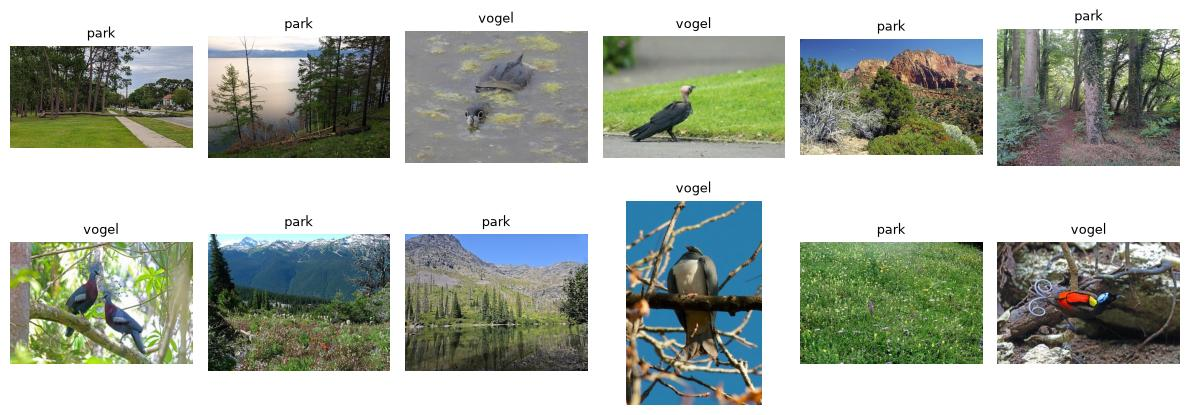

In [2]:
import random
from pathlib import Path

random.seed(7)
beispiele = random.sample(sorted(Path(DATEN).glob("*/*.jpg")), 12)
zeige_bilder(beispiele, [bild.parent.name for bild in beispiele])

## 2. Aufteilen in Training und Validierung

Das Modell lernt nur aus den Trainingsbildern. Die Validierungsbilder halten wir zurück: Sie zeigen später, ob es auch Bilder erkennt, die es nie gesehen hat.

In [3]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.models import ResNet18_Weights

gewichte = ResNet18_Weights.DEFAULT
bilder = ImageFolder(DATEN, transform=gewichte.transforms())

idx_training, idx_validierung = train_test_split(
    range(len(bilder)), test_size=0.2, stratify=bilder.targets, random_state=42
)
training = DataLoader(Subset(bilder, idx_training), batch_size=16, shuffle=True)
validierung = DataLoader(Subset(bilder, idx_validierung), batch_size=32)

print(f"Klassen: {bilder.classes}")
print(f"{len(idx_training)} Bilder zum Trainieren, {len(idx_validierung)} zum Prüfen")

Klassen: ['park', 'vogel']
160 Bilder zum Trainieren, 40 zum Prüfen


## 3. Vortrainiertes Modell laden

ResNet-18 ist ein Bildklassifikator, trainiert auf ImageNet: 1,2 Millionen Fotos in 1'000 Kategorien. Seine Merkmale übernehmen wir unverändert und ersetzen nur die letzte Schicht. Die neue Schicht hat zwei Ausgänge, Park und Vogel, und zufällige Gewichte.

In [4]:
import torch
from torch import nn
from torchvision.models import resnet18

geraet = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

torch.manual_seed(42)
modell = resnet18(weights=gewichte)
for parameter in modell.parameters():
    parameter.requires_grad = False
modell.fc = nn.Linear(modell.fc.in_features, len(bilder.classes))
modell = modell.to(geraet).eval()  # auch die Statistiken der BatchNorm-Schichten bleiben fest

eingefroren = sum(p.numel() for p in modell.parameters() if not p.requires_grad)
lernbar = sum(p.numel() for p in modell.parameters() if p.requires_grad)
print(f"{eingefroren:_} Parameter übernommen, {lernbar:_} Parameter lernen wir".replace("_", "'"))

11'176'512 Parameter übernommen, 1'026 Parameter lernen wir


Vor dem Training sind die Gewichte der neuen Schicht zufällig. Das ist unsere Basislinie: Bei zwei gleich grossen Klassen trifft Raten im Schnitt 50 %.

In [5]:
def trefferquote():
    richtig = 0
    with torch.no_grad():
        for eingabe, label in validierung:
            richtig += (modell(eingabe.to(geraet)).argmax(1).cpu() == label).sum().item()
    return richtig / len(idx_validierung)


print(f"Vor dem Training: {trefferquote():.1%} richtig")

Vor dem Training: 37.5% richtig


## 4. Trainieren

Eine Schleife mit vier Schritten: Vorhersage berechnen, Fehler messen (Loss), Gradient bestimmen, Gewichte anpassen. Ein Durchgang durch alle Trainingsbilder heisst Epoche.

In [6]:
import time

fehlerfunktion = nn.CrossEntropyLoss()
optimierer = torch.optim.Adam(modell.fc.parameters(), lr=0.001)

start = time.perf_counter()
for epoche in range(1, 4):
    summe = 0.0
    for eingabe, label in training:
        eingabe, label = eingabe.to(geraet), label.to(geraet)

        vorhersage = modell(eingabe)              # Vorhersage
        loss = fehlerfunktion(vorhersage, label)  # Fehler messen
        optimierer.zero_grad()
        loss.backward()                           # Gradient
        optimierer.step()                         # Gewichte anpassen

        summe += loss.item() * len(label)

    print(f"Epoche {epoche}: Loss {summe / len(idx_training):.3f}, {trefferquote():.1%} richtig")

print(f"Dauer: {time.perf_counter() - start:.1f} Sekunden")

Epoche 1: Loss 0.566, 97.5% richtig


Epoche 2: Loss 0.212, 97.5% richtig


Epoche 3: Loss 0.108, 97.5% richtig
Dauer: 1.7 Sekunden


## 5. Prüfen und ausprobieren

Alle Validierungsbilder mit der Antwort des Modells, Fehler stehen in Rot.

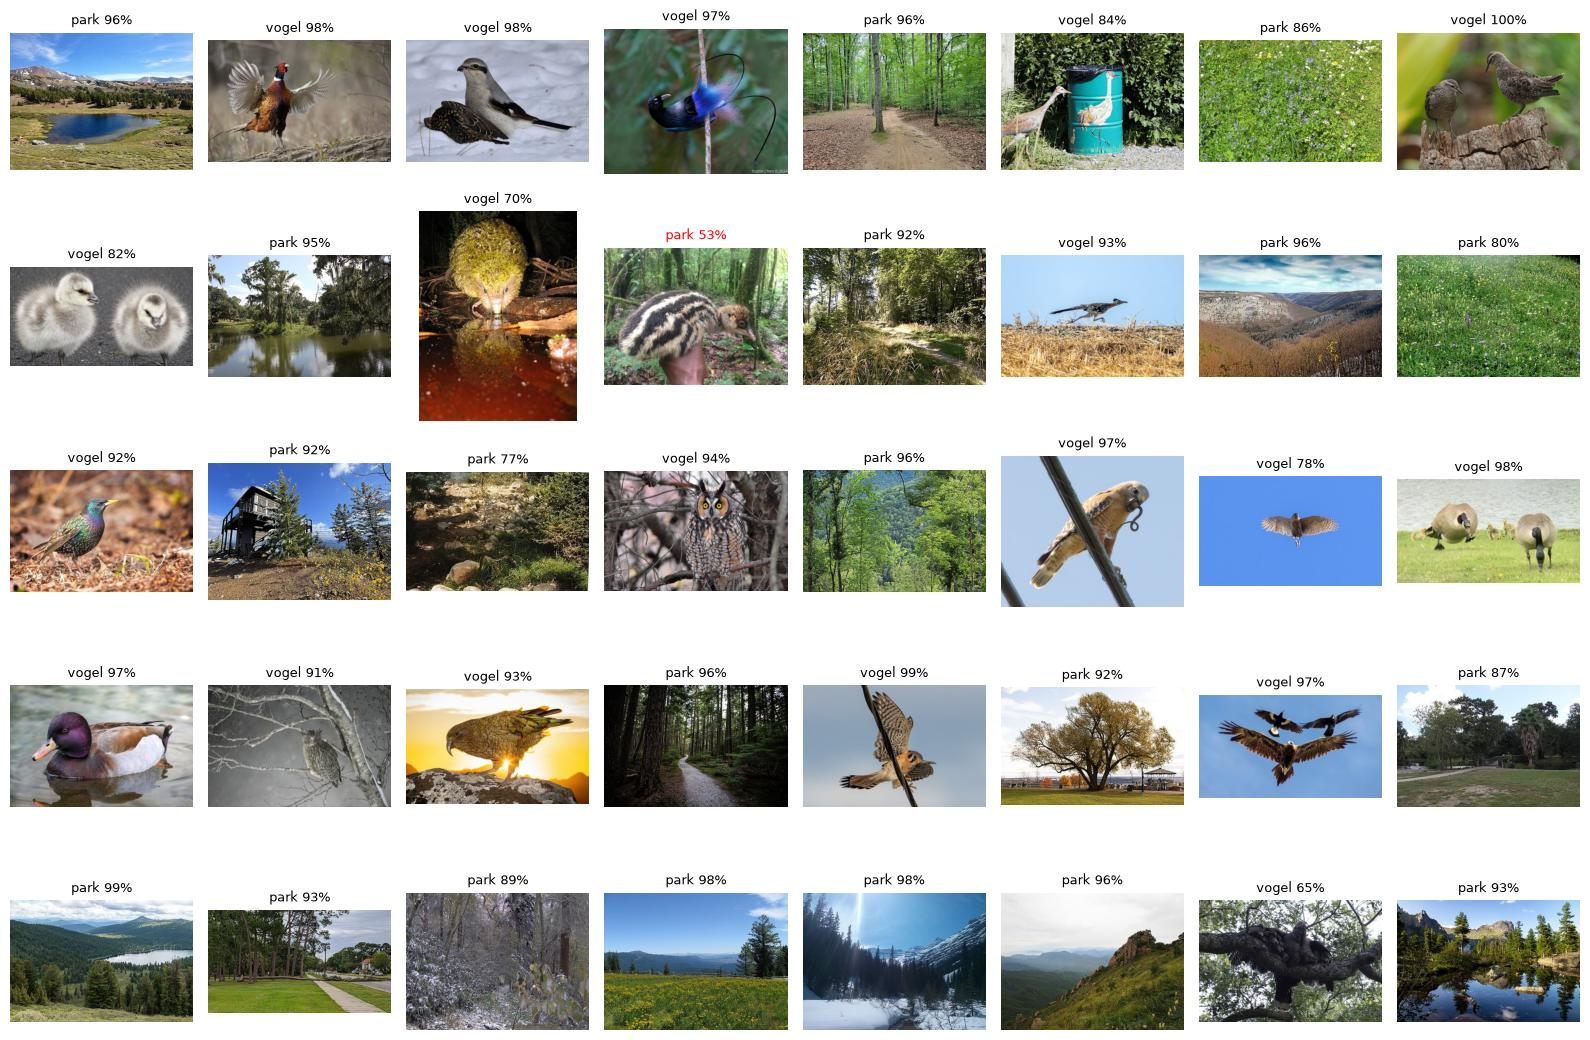

Validierung: 39 von 40 richtig


In [7]:
from PIL import Image


def wahrscheinlichkeiten(pfad):
    bild = gewichte.transforms()(Image.open(pfad).convert("RGB")).unsqueeze(0).to(geraet)
    with torch.no_grad():
        return torch.softmax(modell(bild), dim=1)[0].cpu()


def beschrifte(pfade):
    titel = []
    for pfad in pfade:
        p = wahrscheinlichkeiten(pfad)
        klasse = p.argmax().item()
        titel.append(f"{bilder.classes[klasse]} {p[klasse]:.0%}")
    return titel


pfade = [bilder.samples[i][0] for i in idx_validierung]
wahr = [bilder.classes[bilder.targets[i]] for i in idx_validierung]
titel = beschrifte(pfade)
farben = ["black" if t.split()[0] == w else "red" for t, w in zip(titel, wahr)]

zeige_bilder(pfade, titel, spalten=8, farben=farben)
print(f"Validierung: {farben.count('black')} von {len(pfade)} richtig")

Jetzt schwierige Fälle, die nicht aus dem Training stammen: ein Vogel neben einer Pizza, eine Zeichnung, Tiere im Park, ein Gemälde. Das Modell kennt nur zwei Antworten und muss eine davon geben.

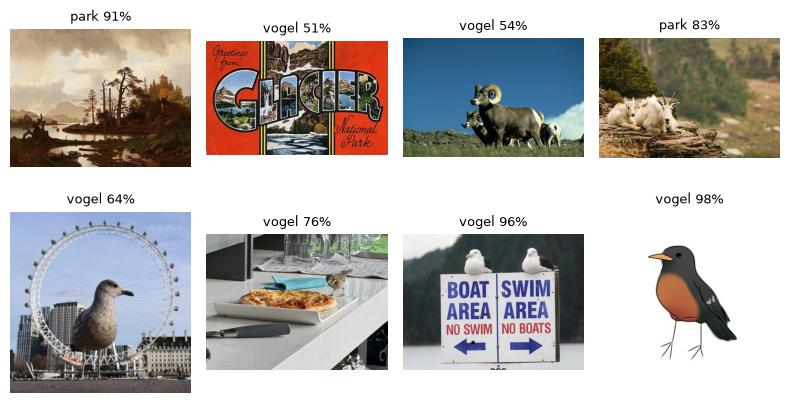

In [8]:
probe = sorted(Path("probe").glob("*.jpg"))
zeige_bilder(probe, beschrifte(probe), spalten=4)

Eigenes Foto ausprobieren: in den Ordner `probe` legen und den Dateinamen unten eintragen.

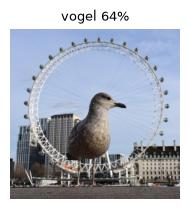

In [9]:
foto = "probe/vogel-london-eye.jpg"
zeige_bilder([foto], beschrifte([foto]), spalten=1)